## Problem Statement

In everyday communication, people make commitments and mention deadlines through emails, messages, meeting notes, and other written conversations. Manually tracking these commitments can be difficult, especially when there are multiple tasks and deadlines.

The system uses NLTK, spaCy, regular expressions, and Python to process and analyze text. It presents the extracted information in a structured table using pandas.

In [50]:
import pandas
import nltk
import spacy
import pandas as pd

print("NLTK Version", nltk.__version__)
print("Spacy Version", spacy.__version__)
print("Pandas Version", pandas.__version__)

NLTK Version 3.10.4
Spacy Version 3.8.18
Pandas Version 3.0.6


In [51]:
nlp = spacy.load("en_core_web_sm")

text = """
I will submit the NLP assignment by Friday.
Ahmed promised to send the project report tomorrow.
Sara needs to finish the presentation before Monday.
My friend may be give a look on project.
"""

doc = nlp(text)
print("ORIGINAL TEXT:")
print(text)
print("Number of sentences: ", len(list(doc.sents)))

ORIGINAL TEXT:

I will submit the NLP assignment by Friday.
Ahmed promised to send the project report tomorrow.
Sara needs to finish the presentation before Monday.
My friend may be give a look on project.

Number of sentences:  4


In [52]:
for tokens in doc:
	print(
		tokens.text,
		"| Pos:", tokens.pos_,
		"| Lemma:", tokens.lemma_,
		"| Dependance:", tokens.dep_
	)


 | Pos: SPACE | Lemma: 
 | Dependance: dep
I | Pos: PRON | Lemma: I | Dependance: nsubj
will | Pos: AUX | Lemma: will | Dependance: aux
submit | Pos: VERB | Lemma: submit | Dependance: ROOT
the | Pos: DET | Lemma: the | Dependance: det
NLP | Pos: PROPN | Lemma: NLP | Dependance: compound
assignment | Pos: NOUN | Lemma: assignment | Dependance: dobj
by | Pos: ADP | Lemma: by | Dependance: prep
Friday | Pos: PROPN | Lemma: Friday | Dependance: pobj
. | Pos: PUNCT | Lemma: . | Dependance: punct

 | Pos: SPACE | Lemma: 
 | Dependance: dep
Ahmed | Pos: PROPN | Lemma: Ahmed | Dependance: nsubj
promised | Pos: VERB | Lemma: promise | Dependance: ROOT
to | Pos: PART | Lemma: to | Dependance: aux
send | Pos: VERB | Lemma: send | Dependance: xcomp
the | Pos: DET | Lemma: the | Dependance: det
project | Pos: NOUN | Lemma: project | Dependance: compound
report | Pos: NOUN | Lemma: report | Dependance: dobj
tomorrow | Pos: NOUN | Lemma: tomorrow | Dependance: npadvmod
. | Pos: PUNCT | Lemma: . | D

In [53]:
import re

commitment_patterns = [
    r"\bi will\b",
    r"\bi'll\b",
    r"\bwill\b",
    r"\bpromised to\b",
    r"\bpromise to\b",
    r"\bneeds to\b",
    r"\bneed to\b",
    r"\bmust\b",
    r"\bhave to\b",
    r"\bhas to\b",
    r"\bshould\b"
]

print("Commitment patterns created:", len(commitment_patterns))

Commitment patterns created: 11


In [54]:
def detect_commitment(sentences):
	for pattern in commitment_patterns:
		if re.search(pattern,sentences,re.IGNORECASE):
			return True

	return False

In [55]:
test_sentences = [
    "I will submit the NLP assignment.",
    "Ahmed promised to send the project report.",
    "Sara needs to finish the presentation.",
    "I must complete my homework.",
    "The weather is pleasant today.",
    "We went to the university yesterday."
]

for sentence in test_sentences:
	result = detect_commitment(sentence)
	print("Sentence:",sentence)
	print("Commitment detected:",result)
	print("-"*50)

Sentence: I will submit the NLP assignment.
Commitment detected: True
--------------------------------------------------
Sentence: Ahmed promised to send the project report.
Commitment detected: True
--------------------------------------------------
Sentence: Sara needs to finish the presentation.
Commitment detected: True
--------------------------------------------------
Sentence: I must complete my homework.
Commitment detected: True
--------------------------------------------------
Sentence: The weather is pleasant today.
Commitment detected: False
--------------------------------------------------
Sentence: We went to the university yesterday.
Commitment detected: False
--------------------------------------------------


In [56]:
for sentence in doc.sents:
	sentence_text = sentence.text.strip()

	if detect_commitment(sentence_text):
		print("Commitment: ", sentence_text)
	else:
		print("Not detected: ", sentence_text)


Commitment:  I will submit the NLP assignment by Friday.
Commitment:  Ahmed promised to send the project report tomorrow.
Commitment:  Sara needs to finish the presentation before Monday.
Not detected:  My friend may be give a look on project.


In [57]:
def extract_action(sentence):
    doc = nlp(sentence)

    for token in doc:
        if token.lemma_ in ["submit", "send", "finish", "complete",
                            "prepare", "deliver", "review", "write",
                            "create", "attend", "upload", "pay"]:

            action = []

            for child in token.children:
                if child.dep_ in ["dobj", "obj", "attr"]:
                    action.append(child.text)

                    for subchild in child.subtree:
                        if subchild != child:
                            action.append(subchild.text)

            if action:
                return token.text + " " + " ".join(action)

            return token.text

    return None

In [58]:
test_sentences = [
    "I will submit the NLP assignment by Friday.",
    "Ahmed promised to send the project report tomorrow.",
    "Sara needs to finish the presentation before Monday.",
				"I will prepare the project presentation by Thursday.",
    "I must complete my homework."
]

for sentence in test_sentences:
    print("Input:", sentence)
    print("Action:", extract_action(sentence))
    print("-" * 50)

Input: I will submit the NLP assignment by Friday.
Action: submit assignment the NLP
--------------------------------------------------
Input: Ahmed promised to send the project report tomorrow.
Action: send report the project
--------------------------------------------------
Input: Sara needs to finish the presentation before Monday.
Action: finish presentation the
--------------------------------------------------
Input: I will prepare the project presentation by Thursday.
Action: prepare presentation the project
--------------------------------------------------
Input: I must complete my homework.
Action: complete homework my
--------------------------------------------------


In [59]:
import re

deadline_patterns = [
    r"\bby\s+(?:next\s+)?(?:Monday|Tuesday|Wednesday|Thursday|Friday|Saturday|Sunday)\b",
				r"\bwithin\s+(?:\d+|one|two|three|four|five)\s+(?:day|days|week|weeks)\b",
    r"\bbefore\s+(?:next\s+)?(?:Monday|Tuesday|Wednesday|Thursday|Friday|Saturday|Sunday)\b",
    r"\bon\s+(?:next\s+)?(?:Monday|Tuesday|Wednesday|Thursday|Friday|Saturday|Sunday)\b",
    r"\b(?:today|tomorrow|tonight|tonight|yesterday)\b",
    r"\bnext\s+(?:week|month|year)\b",
    r"\bin\s+\d+\s+(?:day|days|week|weeks|month|months)\b",
    r"\bby\s+\d{1,2}[/-]\d{1,2}(?:[/-]\d{2,4})?\b",
    r"\bby\s+\d{1,2}\s+(?:January|February|March|April|May|June|July|August|September|October|November|December)\b",
]

print("Deadline patterns created:", len(deadline_patterns))

Deadline patterns created: 9


In [60]:
def extract_deadline(sentence):
    for pattern in deadline_patterns:
        match = re.search(pattern, sentence, re.IGNORECASE)

        if match:
            return match.group(0)

    return None

In [61]:
test_sentences = [
    "I will submit the NLP assignment by Friday.",
    "Ahmed will send the report tomorrow.",
    "Sara must finish the presentation before Monday.",
    "I will complete the project in 3 days.",
    "We should finish this next week.",
    "I will attend the meeting today.",
    "I enjoy learning Python."
]

for sentence in test_sentences:
    print("Input:", sentence)
    print("Deadline:", extract_deadline(sentence))
    print("-" * 50)

Input: I will submit the NLP assignment by Friday.
Deadline: by Friday
--------------------------------------------------
Input: Ahmed will send the report tomorrow.
Deadline: tomorrow
--------------------------------------------------
Input: Sara must finish the presentation before Monday.
Deadline: before Monday
--------------------------------------------------
Input: I will complete the project in 3 days.
Deadline: in 3 days
--------------------------------------------------
Input: We should finish this next week.
Deadline: next week
--------------------------------------------------
Input: I will attend the meeting today.
Deadline: today
--------------------------------------------------
Input: I enjoy learning Python.
Deadline: None
--------------------------------------------------


In [62]:
test_sentences = [
    "I will submit the assignment by Friday.",
    "I will submit the assignment Friday.",
    "I will finish it within two days.",
    "I will complete the work on 12 November."
]

for sentence in test_sentences:
    print(sentence)
    print("Deadline:", extract_deadline(sentence))
    print("-" * 50)

I will submit the assignment by Friday.
Deadline: by Friday
--------------------------------------------------
I will submit the assignment Friday.
Deadline: None
--------------------------------------------------
I will finish it within two days.
Deadline: within two days
--------------------------------------------------
I will complete the work on 12 November.
Deadline: None
--------------------------------------------------


In [63]:
def extract_person(sentence):
    doc = nlp(sentence)

    # First: Named Entity Recognition
    for ent in doc.ents:
        if ent.label_ == "PERSON":
            return ent.text

    # Second: Grammatical subject detection
    for token in doc:
        if token.dep_ in ["nsubj", "nsubjpass"] and token.pos_ == "PROPN":
            return token.text

    return "Unknown"

In [64]:
person_tests = [
    "Ahmed promised to send the project report tomorrow.",
    "Sara needs to finish the presentation before Monday.",
    "I will submit the NLP assignment by Friday."
]

for sentence in person_tests:
    print("Sentence:", sentence)
    print("Person:", extract_person(sentence))
    print("-" * 40)

Sentence: Ahmed promised to send the project report tomorrow.
Person: Ahmed
----------------------------------------
Sentence: Sara needs to finish the presentation before Monday.
Person: Sara
----------------------------------------
Sentence: I will submit the NLP assignment by Friday.
Person: Unknown
----------------------------------------


In [65]:
def extract_commitment_info(sentence):
    is_commitment = detect_commitment(sentence)

    result = {
        "Sentence": sentence,
        "Commitment Detected": is_commitment,
        "Responsible Person": "Unknown",
        "Action": None,
        "Deadline": None
    }

    if is_commitment:
        result["Responsible Person"] = extract_person(sentence)
        result["Action"] = extract_action(sentence)
        result["Deadline"] = extract_deadline(sentence)

    return result

In [66]:
sample_messages = [
    "Ahmed promised to send the project report tomorrow.",
    "I will submit the NLP assignment by Friday.",
    "Sara needs to finish the presentation before Monday.",
    "The weather is pleasant today.",
    "I must complete my homework within two days."
]

results = []

for message in sample_messages:
    result = extract_commitment_info(message)
    results.append(result)

for result in results:
    print(result)
    print("-" * 60)

{'Sentence': 'Ahmed promised to send the project report tomorrow.', 'Commitment Detected': True, 'Responsible Person': 'Ahmed', 'Action': 'send report the project', 'Deadline': 'tomorrow'}
------------------------------------------------------------
{'Sentence': 'I will submit the NLP assignment by Friday.', 'Commitment Detected': True, 'Responsible Person': 'Unknown', 'Action': 'submit assignment the NLP', 'Deadline': 'by Friday'}
------------------------------------------------------------
{'Sentence': 'Sara needs to finish the presentation before Monday.', 'Commitment Detected': True, 'Responsible Person': 'Sara', 'Action': 'finish presentation the', 'Deadline': 'before Monday'}
------------------------------------------------------------
{'Sentence': 'The weather is pleasant today.', 'Commitment Detected': False, 'Responsible Person': 'Unknown', 'Action': None, 'Deadline': None}
------------------------------------------------------------
{'Sentence': 'I must complete my homework w

In [67]:
from IPython.display import display

df = pd.DataFrame(results)

display(df)

,Sentence,Commitment Detected,Responsible Person,Action,Deadline
0,Ahmed promised to send the project report tomo...,True,Ahmed,send report the project,tomorrow
1,I will submit the NLP assignment by Friday.,True,Unknown,submit assignment the NLP,by Friday
2,Sara needs to finish the presentation before M...,True,Sara,finish presentation the,before Monday
3,The weather is pleasant today.,False,Unknown,NaN,NaN
4,I must complete my homework within two days.,True,Unknown,complete homework my,within two days


In [68]:
evaluation_data = [
    ("I will submit the assignment by Friday.", 1),
    ("Ahmed promised to send the report tomorrow.", 1),
    ("Sara needs to finish the presentation.", 1),
    ("I must complete my homework.", 1),
    ("We have to prepare the project.", 1),
    ("Bilal should review the document.", 1),
    ("I need to upload the files today.", 1),
    ("They will deliver the materials next week.", 1),
    ("I have to attend the meeting.", 1),
    ("She promised to call me tomorrow.", 1),

    ("The weather is pleasant today.", 0),
    ("I enjoy learning Python.", 0),
    ("The university is closed today.", 0),
    ("Ahmed likes playing cricket.", 0),
    ("The report is available online.", 0),
    ("We visited the university yesterday.", 0),
    ("The meeting was interesting.", 0),
    ("I am studying computer science.", 0),
    ("The weather will be pleasant tomorrow.", 0),
    ("We will see you at the university.", 0)
]

print("Total test sentences:", len(evaluation_data))

Total test sentences: 20


In [69]:
actual_labels = []
predicted_labels = []

for sentence, actual in evaluation_data:

    prediction = detect_commitment(sentence)

    actual_labels.append(actual)
    predicted_labels.append(int(prediction))

print("Evaluation completed!")

Evaluation completed!


In [70]:
evaluation_results = pd.DataFrame({
    "Sentence": [item[0] for item in evaluation_data],
    "Actual": actual_labels,
    "Predicted": predicted_labels
})

evaluation_results["Correct"] = (
    evaluation_results["Actual"] ==
    evaluation_results["Predicted"]
)

display(evaluation_results)

,Sentence,Actual,Predicted,Correct
0,I will submit the assignment by Friday.,1,1,True
1,Ahmed promised to send the report tomorrow.,1,1,True
2,Sara needs to finish the presentation.,1,1,True
3,I must complete my homework.,1,1,True
4,We have to prepare the project.,1,1,True
5,Bilal should review the document.,1,1,True
6,I need to upload the files today.,1,1,True
7,They will deliver the materials next week.,1,1,True
8,I have to attend the meeting.,1,1,True
9,She promised to call me tomorrow.,1,1,True


In [71]:
TP = 0
FP = 0
TN = 0
FN = 0

for actual, predicted in zip(actual_labels, predicted_labels):

    if actual == 1 and predicted == 1:
        TP += 1

    elif actual == 0 and predicted == 1:
        FP += 1

    elif actual == 0 and predicted == 0:
        TN += 1

    elif actual == 1 and predicted == 0:
        FN += 1

print("True Positives:", TP)
print("False Positives:", FP)
print("True Negatives:", TN)
print("False Negatives:", FN)

True Positives: 10
False Positives: 2
True Negatives: 8
False Negatives: 0


In [ ]:
precision = TP / (TP + FP) if (TP + FP) > 0 else 0

recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

accuracy = (TP + TN) / len(actual_labels)

print("Accuracy: ", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:   ", round(recall * 100, 2), "%")
print("F1-score: ", round(f1_score * 100, 2), "%")

Accuracy:  90.0 %
Precision: 83.33 %
Recall:    0.0 %
F1-score:  0.0 %


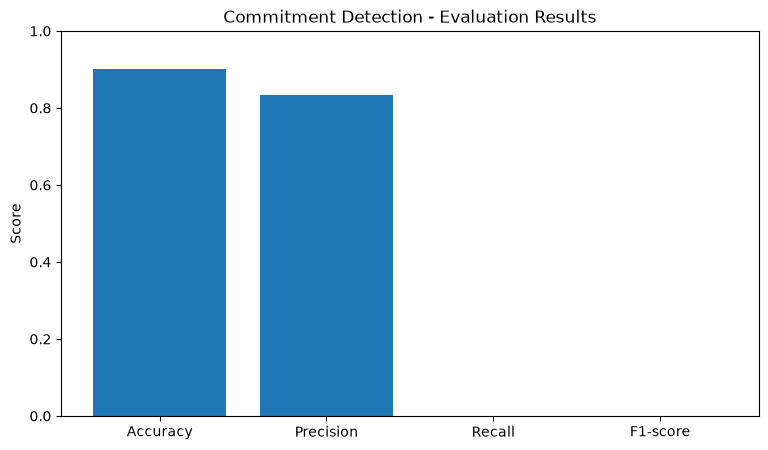

In [73]:
import matplotlib.pyplot as plt

metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1_score
}

plt.figure(figsize=(9, 5))

plt.bar(metrics.keys(), metrics.values())

plt.title("Commitment Detection - Evaluation Results")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.show()

In [74]:
incorrect_predictions = evaluation_results[
    evaluation_results["Correct"] == False
]

print("Incorrect predictions:", len(incorrect_predictions))

display(incorrect_predictions)

Incorrect predictions: 2


,Sentence,Actual,Predicted,Correct
18,The weather will be pleasant tomorrow.,0,1,False
19,We will see you at the university.,0,1,False
